In [1]:

import pandas as pd

# Load the UCI Bank Marketing dataset
bank = pd.read_csv("bank-full.csv", sep=";")

# Check that the dataset loaded successfully
print("Dataset shape:", bank.shape)

display(bank.head())


Dataset shape: (45211, 17)


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [2]:

# Check the number of rows and columns
print("Dataset shape:", bank.shape)

# Display column names and data types
print("\nDataset information:")
bank.info()

# Display summary statistics
print("\nNumerical summary:")
display(bank.describe())


Dataset shape: (45211, 17)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB

Numerical summary:


,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [3]:

# Check for missing values
print("Missing values in each column:")
print(bank.isnull().sum())

# Check for duplicate records
print("\nDuplicate records:")
print(bank.duplicated().sum())

# Check for 'unknown' values in categorical columns
categorical_columns = bank.select_dtypes(
    include=["object"]
).columns

print("\nUnknown values:")
for column in categorical_columns:
    count = (bank[column] == "unknown").sum()
    if count > 0:
        print(f"{column}: {count}")


Missing values in each column:
age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64

Duplicate records:
0

Unknown values:
job: 288
education: 1857
contact: 13020
poutcome: 36959


Target distribution:
y
no     39922
yes     5289
Name: count, dtype: int64

Target percentages:
y
no     88.30152
yes    11.69848
Name: proportion, dtype: float64


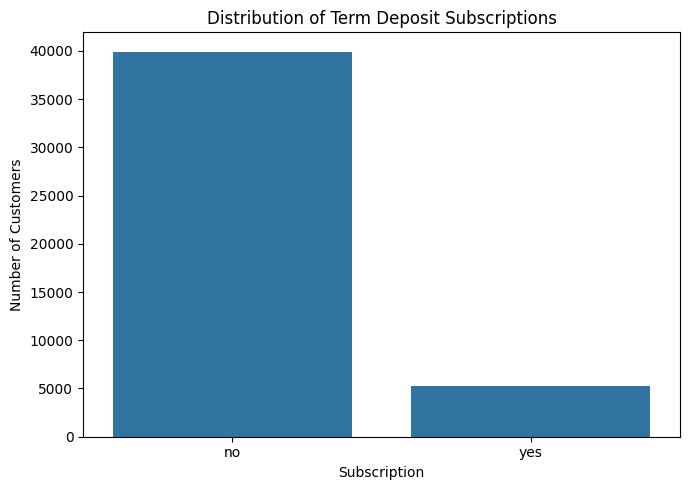

In [4]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count customers who subscribed and did not subscribe
print("Target distribution:")
print(bank["y"].value_counts())

print("\nTarget percentages:")
print(bank["y"].value_counts(normalize=True) * 100)

# Visualise class distribution
plt.figure(figsize=(7, 5))

sns.countplot(
    data=bank,
    x="y",
    order=["no", "yes"]
)

plt.title("Distribution of Term Deposit Subscriptions")
plt.xlabel("Subscription")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()


In [5]:

from sklearn.model_selection import train_test_split

train_bank, test_bank = train_test_split(
    bank,
    test_size=0.2,
    random_state=42,
    stratify=bank["y"]
)

print("Training dataset:", train_bank.shape)
print("Testing dataset:", test_bank.shape)

print("\nTraining target distribution:")
print(train_bank["y"].value_counts(normalize=True) * 100)

print("\nTesting target distribution:")
print(test_bank["y"].value_counts(normalize=True) * 100)


Training dataset: (36168, 17)
Testing dataset: (9043, 17)

Training target distribution:
y
no     88.301814
yes    11.698186
Name: proportion, dtype: float64

Testing target distribution:
y
no     88.300343
yes    11.699657
Name: proportion, dtype: float64


In [6]:

# Identify numerical columns in the training dataset
numerical_columns = train_bank.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

# Summary statistics for numerical features
display(train_bank[numerical_columns].describe())


Numerical columns:
['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']


,age,balance,day,duration,campaign,pdays,previous
count,36168.000000,36168.00000,36168.000000,36168.000000,36168.000000,36168.000000,36168.000000
mean,40.892999,1365.49342,15.817961,258.506940,2.763935,40.157238,0.581730
std,10.627075,3068.54350,8.331980,259.142445,3.104161,100.162614,2.408766
min,18.000000,-8019.00000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,74.00000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,451.00000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1430.25000,21.000000,318.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.00000,31.000000,4918.000000,63.000000,871.000000,275.000000


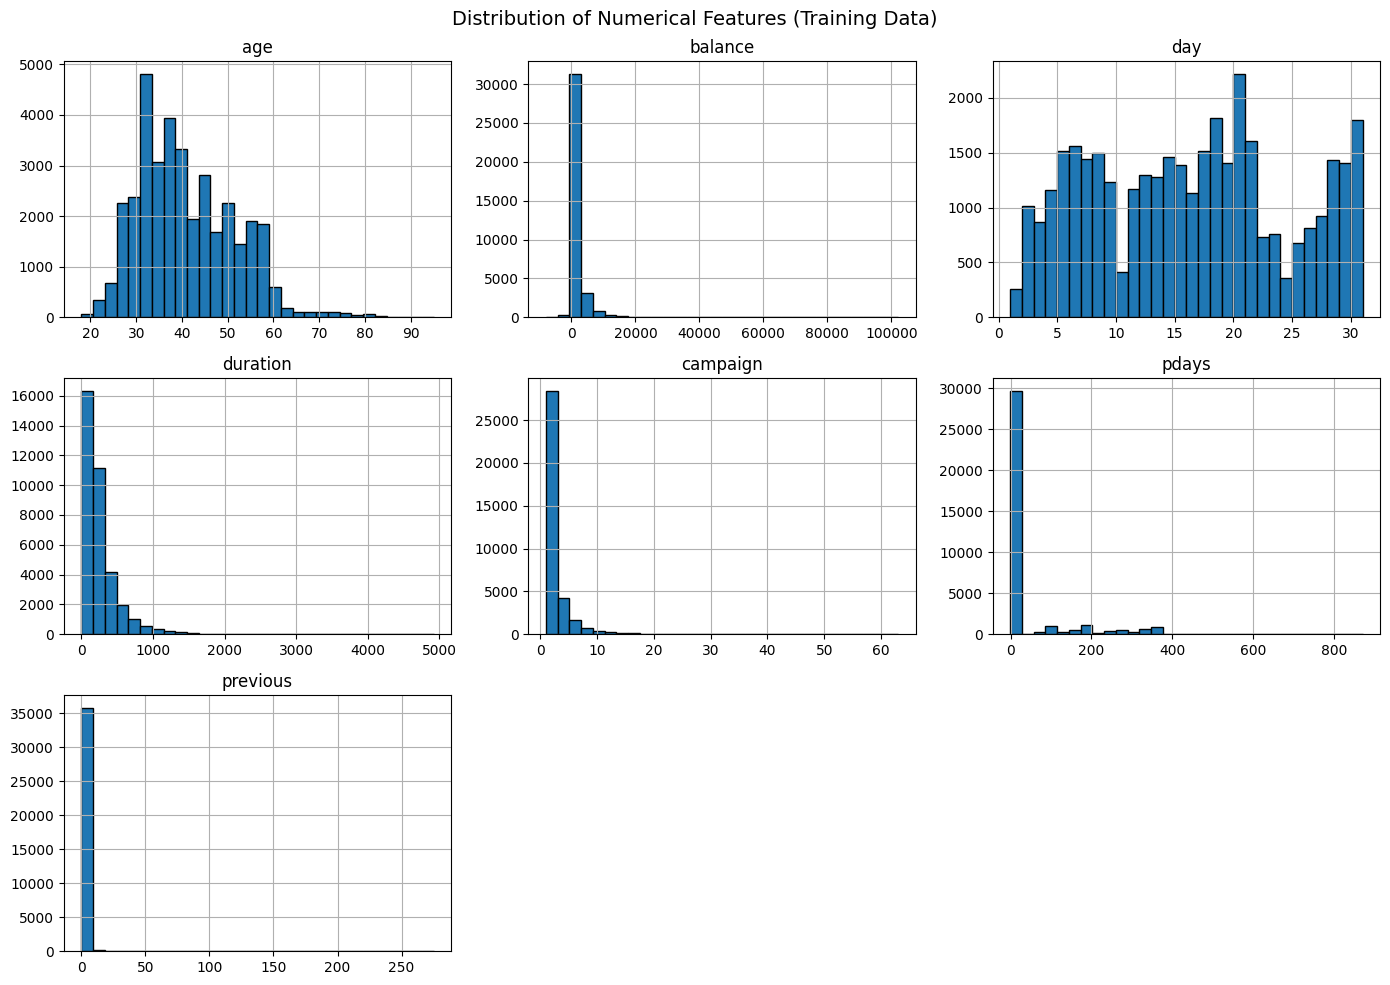

In [7]:

# Plot histograms for numerical features
train_bank[numerical_columns].hist(
    bins=30,
    figsize=(14, 10),
    edgecolor="black"
)

plt.suptitle(
    "Distribution of Numerical Features (Training Data)",
    fontsize=14
)

plt.tight_layout()
plt.show()


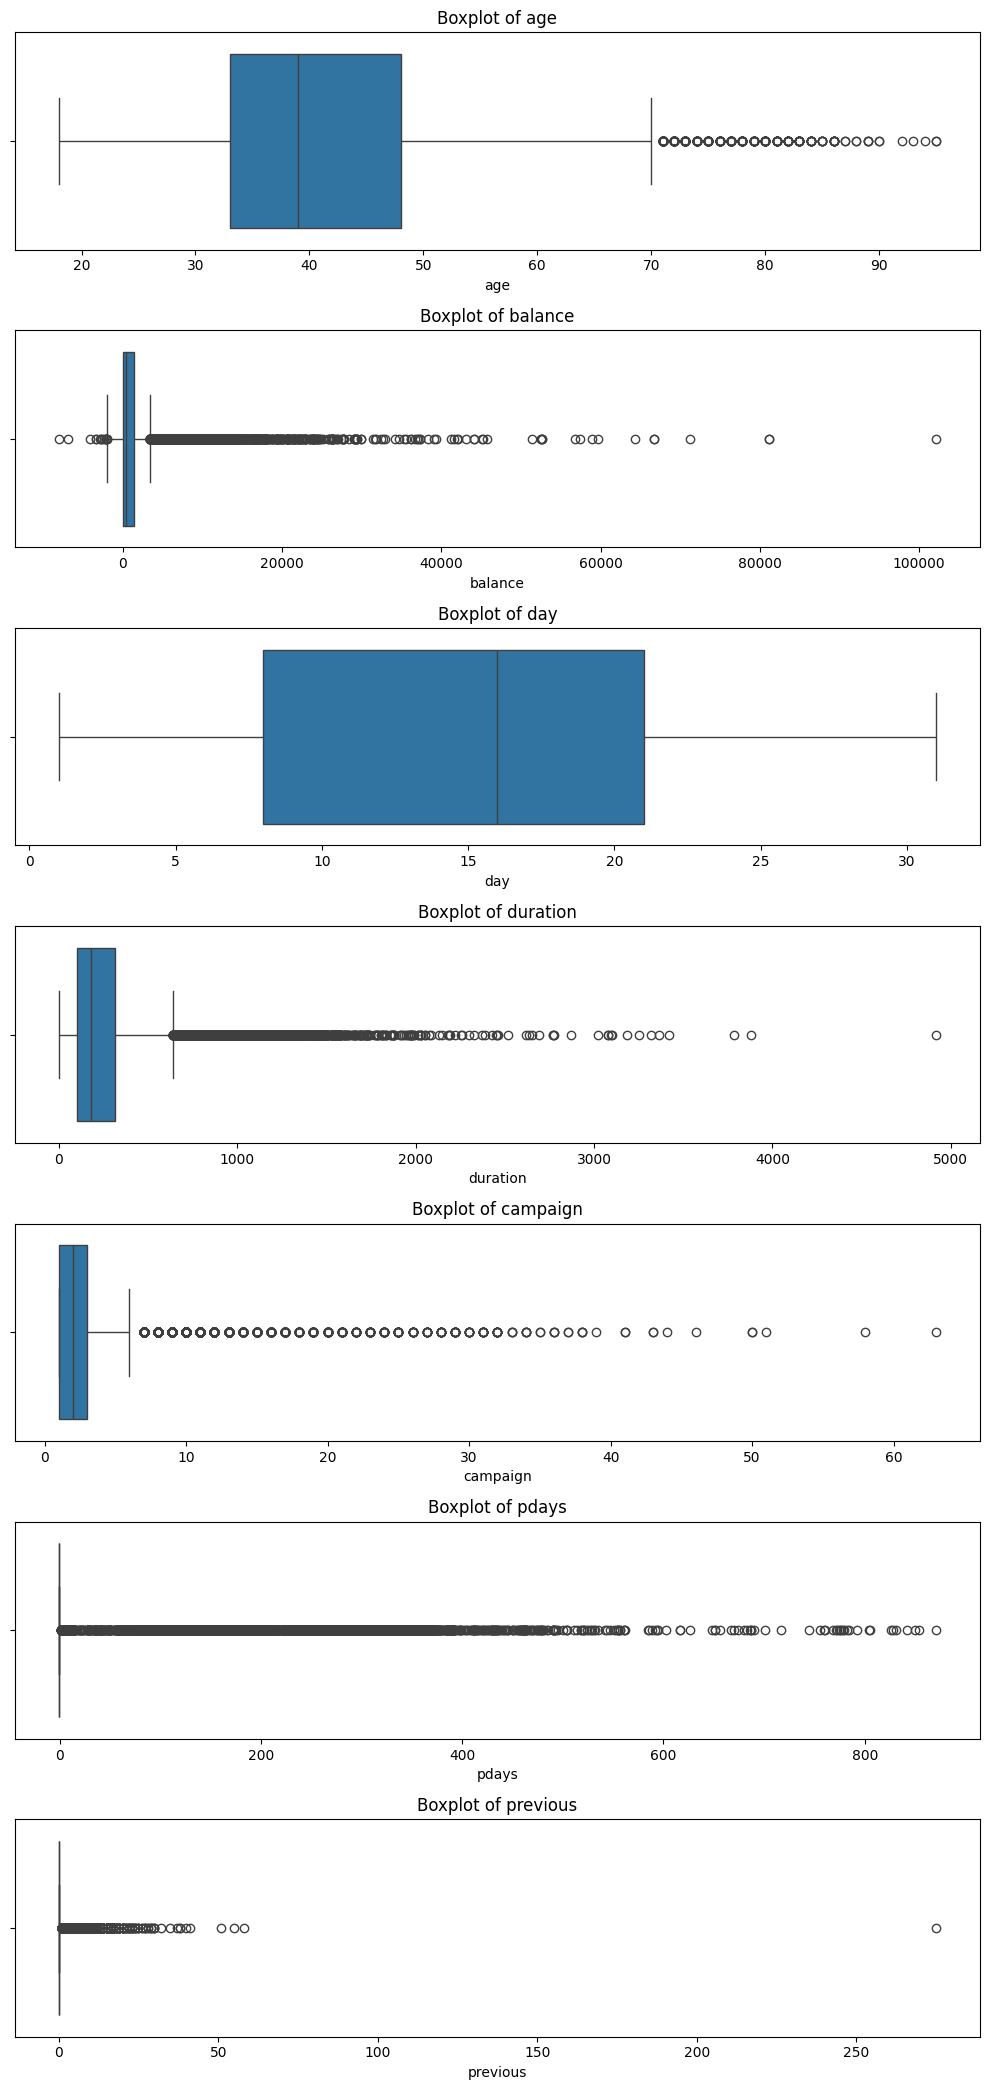

In [8]:

# Visualise potential outliers using boxplots
fig, axes = plt.subplots(
    len(numerical_columns),
    1,
    figsize=(10, 3 * len(numerical_columns))
)

for ax, column in zip(axes, numerical_columns):
    sns.boxplot(
        x=train_bank[column],
        ax=ax
    )
    ax.set_title(f"Boxplot of {column}")

plt.tight_layout()
plt.show()


In [9]:

# Identify categorical columns
categorical_columns = train_bank.select_dtypes(
    include=["object"]
).columns.drop("y").tolist()

print("Categorical columns:")
print(categorical_columns)

# Display category frequencies
for column in categorical_columns:
    print(f"\n{column}:")
    print(train_bank[column].value_counts())


Categorical columns:
['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'poutcome']

job:
job
blue-collar      7830
management       7511
technician       6068
admin.           4141
services         3348
retired          1812
self-employed    1243
entrepreneur     1186
unemployed       1024
housemaid        1013
student           758
unknown           234
Name: count, dtype: int64

marital:
marital
married     21771
single      10227
divorced     4170
Name: count, dtype: int64

education:
education
secondary    18561
tertiary     10594
primary       5531
unknown       1482
Name: count, dtype: int64

default:
default
no     35521
yes      647
Name: count, dtype: int64

housing:
housing
yes    20182
no     15986
Name: count, dtype: int64

loan:
loan
no     30355
yes     5813
Name: count, dtype: int64

contact:
contact
cellular     23465
unknown      10386
telephone     2317
Name: count, dtype: int64

month:
month
may    11062
jul     5537
aug     4986
jun  

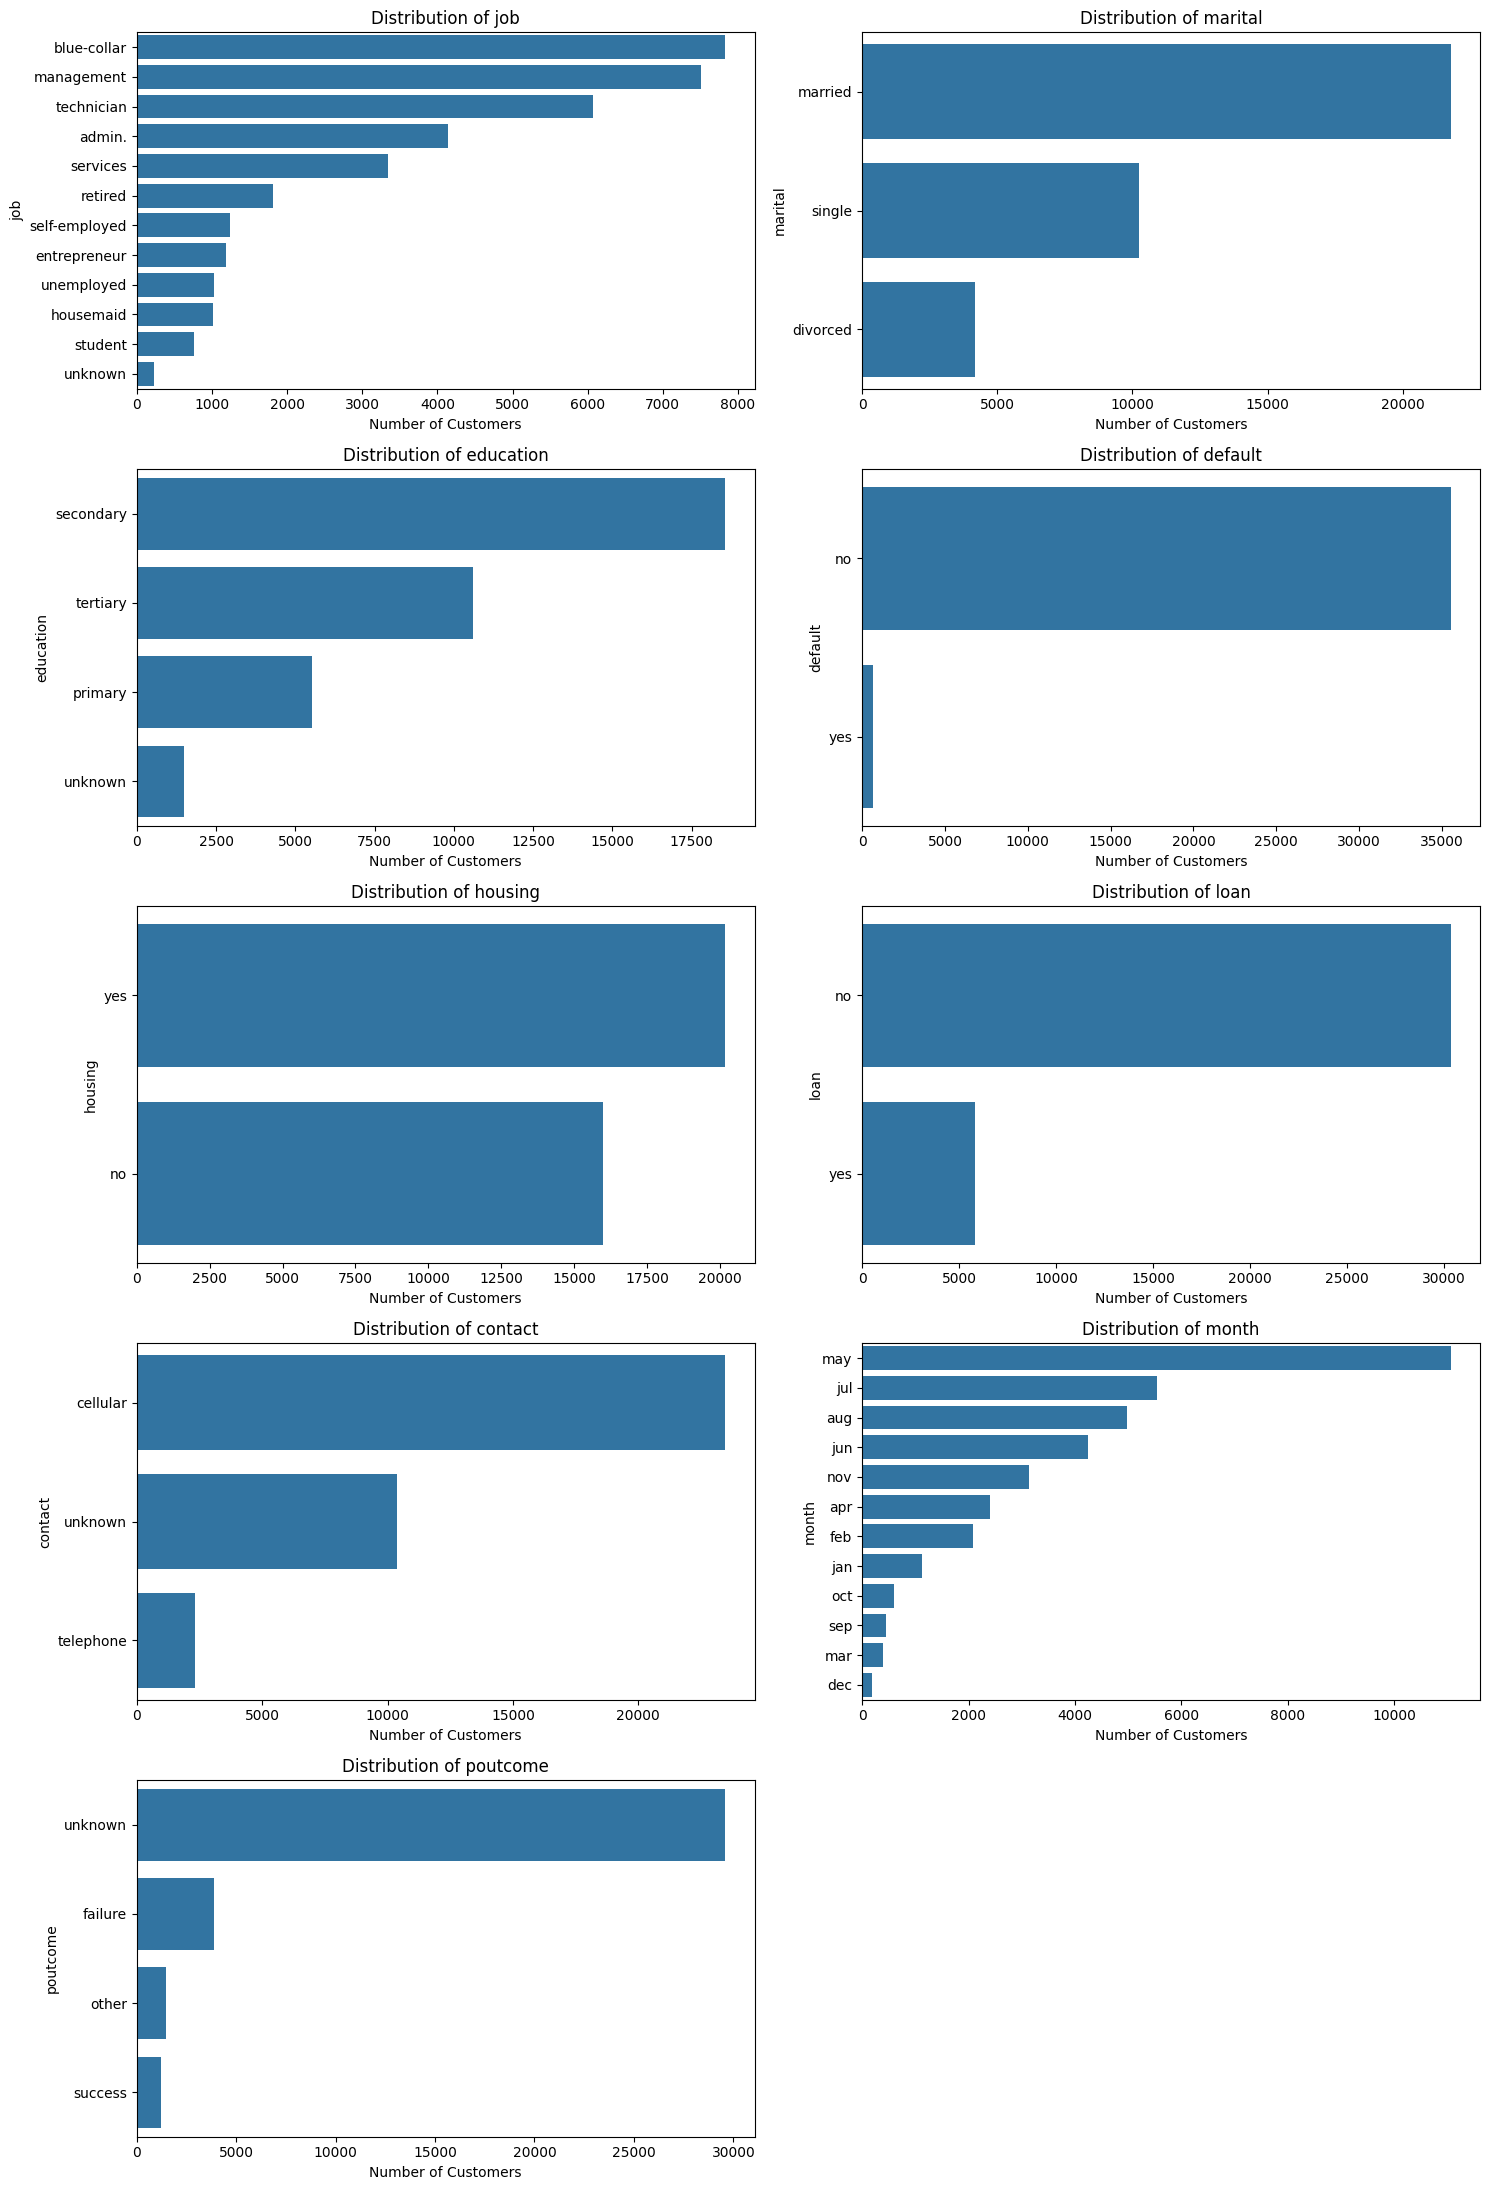

In [11]:

# Plot categorical feature distributions
fig, axes = plt.subplots(
    5, 2,
    figsize=(15, 22)
)

axes = axes.flatten()

for i, column in enumerate(categorical_columns):
    sns.countplot(
        data=train_bank,
        y=column,
        ax=axes[i],
        order=train_bank[column].value_counts().index
    )
    axes[i].set_title(f"Distribution of {column}")
    axes[i].set_xlabel("Number of Customers")

# Remove the unused tenth subplot
fig.delaxes(axes[-1])

plt.tight_layout()
plt.show()
